In [1]:
import pandas as pd
from tabulate import tabulate
import matplotlib.pyplot as plt
import numpy as np
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv(r'USA_Supply_data.csv', encoding="latin-1")
pd.set_option("display.max_columns", None)

Data Cleaning

In [3]:
df["delay_days"] = (df["Days for shipping (real)"] - df["Days for shipment (scheduled)"]).clip(lower=0)

route_cols = ["Customer State", "Customer City",
              "Order Region", "Order State", "Order City",
              "Shipping Mode"]

route_kpis = (
    df.groupby(route_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          profit_sum=("Order Profit Per Order", "sum"),
          profit_mean=("Order Profit Per Order", "mean"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

min_orders = 30
worst_routes = (
    route_kpis.query("n_orders >= @min_orders")
              .sort_values("profit_sum")
              .head(20)
)

route_product_cols = route_cols + ["Category Name", "Department Name"]
route_product_kpis = (
    df.groupby(route_product_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          units=("Order Item Quantity", "sum"),
          profit_sum=("Order Profit Per Order", "sum"),
          profit_mean=("Order Profit Per Order", "mean"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

route_product_segment_cols = route_cols + ["Customer Segment", "Category Name", "Department Name"]
route_prod_seg_kpis = (
    df.groupby(route_product_segment_cols)
      .agg(
          n_orders=("Order Id", "nunique"),
          profit_sum=("Order Profit Per Order", "sum"),
          late_rate=("Late_delivery_risk", "mean"),
          p90_delay=("delay_days", lambda x: x.quantile(0.90)),
      )
      .reset_index()
)

In [4]:
df.head(5)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,Customer Country,Customer Id,Customer Segment,Customer State,Customer Street,Customer Zipcode,Department Id,Department Name,Latitude,Longitude,Market,Order City,Order Country,Order Customer Id,order date (DateOrders),Order Id,Order Item Cardprod Id,Order Item Discount,Order Item Discount Rate,Order Item Id,Order Item Product Price,Order Item Profit Ratio,Order Item Quantity,Sales,Order Item Total,Order Profit Per Order,Order Region,Order State,Order Status,Order Zipcode,Product Card Id,Product Category Id,Product Image,Product Name,Product Price,Product Status,shipping date (DateOrders),Shipping Mode,Name,delay_days
0,PAYMENT,2,2,22.41,74.680000,Shipping on time,0,13,Electronics,Caguas,Puerto Rico,3296,Home Office,PR,8205 Silver Grove Row,725,3,Footwear,18.234663,-66.370598,USCA,Pasco,Estados Unidos,3296,06/11/2016 15:12,36146,278,15.300000,0.17,90273,44.990002,0.30,2,89.980003,74.680000,22.41,West of USA,Washington,PENDING_PAYMENT,99301,278,13,http://images.acmesports.sports/Under+Armour+M...,Under Armour Men's Compression EV SL Slide,44.990002,0,6/13/2016 15:12,Second Class,Mary Smith,0
1,PAYMENT,5,2,25.24,90.150002,Late delivery,1,12,Boxing & MMA,Caguas,Puerto Rico,3182,Home Office,PR,7786 Middle Private,725,3,Footwear,18.262682,-66.370499,USCA,Los Angeles,Estados Unidos,3182,8/24/2016 21:45,41234,249,19.790001,0.18,102921,54.970001,0.28,2,109.940002,90.150002,25.24,West of USA,California,PENDING_PAYMENT,90049,249,12,http://images.acmesports.sports/Under+Armour+W...,Under Armour Women's Micro G Skulpt Running S,54.970001,0,8/29/2016 21:45,Second Class,Frances Smith,3
2,PAYMENT,6,2,30.57,117.580002,Late delivery,1,17,Cleats,Caguas,Puerto Rico,7864,Home Office,PR,4294 High Passage,725,4,Apparel,18.282795,-66.370560,USCA,San Francisco,Estados Unidos,7864,4/13/2016 10:12,32090,365,2.400000,0.02,80250,59.990002,0.26,2,119.980003,117.580002,30.57,West of USA,California,PENDING_PAYMENT,94110,365,17,http://images.acmesports.sports/Perfect+Fitnes...,Perfect Fitness Perfect Rip Deck,59.990002,0,4/19/2016 10:12,Second Class,Alice Smith,4
3,PAYMENT,4,2,46.07,95.980003,Late delivery,1,17,Cleats,Caguas,Puerto Rico,11169,Home Office,PR,5274 Easy Beach,725,4,Apparel,18.274662,-66.370583,USCA,Overland Park,Estados Unidos,11169,5/22/2016 14:10,34773,365,24.000000,0.20,86866,59.990002,0.48,2,119.980003,95.980003,46.07,US Center,Kansas,PENDING_PAYMENT,66212,365,17,http://images.acmesports.sports/Perfect+Fitnes...,Perfect Fitness Perfect Rip Deck,59.990002,0,5/26/2016 14:10,Second Class,Kyle Thomas,2
4,TRANSFER,5,4,28.85,128.220001,Shipping canceled,0,13,Electronics,Freeport,EE. UU.,1509,Consumer,NY,3675 Emerald Goose Bank,11520,3,Footwear,40.654865,-73.587074,USCA,Houston,Estados Unidos,1509,05/08/2016 17:42,33824,278,6.750000,0.05,84424,44.990002,0.23,3,134.970001,128.220001,28.85,US Center,Texas,SUSPECTED_FRAUD,77041,278,13,http://images.acmesports.sports/Under+Armour+M...,Under Armour Men's Compression EV SL Slide,44.990002,0,5/13/2016 17:42,Standard Class,Patricia Petersen,1


Routes where we are losing money

In [5]:
route_coords = (
    df.groupby(route_cols)
      .agg(
          order_longitude=("Longitude", "median"),
          order_latitude=("Latitude", "median"),
      )
      .reset_index()
)

In [6]:
route_kpis_full = route_kpis.merge(route_coords, on=route_cols, how="left")

In [7]:
display_cols = [
    "Customer State", "Customer City",
    "Order Region", "Order State", "Order City",
    "order_longitude", "order_latitude",
    "Shipping Mode",
    "profit_sum", "late_rate", "p90_delay"
]

final_df = route_kpis_full[display_cols]

display(final_df)

,Customer State,Customer City,Order Region,Order State,Order City,order_longitude,order_latitude,Shipping Mode,profit_sum,late_rate,p90_delay
0,AL,Birmingham,East of USA,Nueva Jersey,Morristown,-86.680969,33.620781,Standard Class,101.619996,1.0,1.0
1,AL,Birmingham,South of USA,Virginia,Waynesboro,-86.680969,33.620781,Standard Class,183.480004,0.0,0.0
2,AL,Birmingham,US Center,Illinois,Orland Park,-86.680969,33.620781,First Class,-11.329997,1.0,1.0
3,AL,Birmingham,West of USA,Washington,Seattle,-86.680969,33.620781,First Class,158.139999,1.0,1.0
4,AR,Conway,East of USA,Ohio,Lancaster,-92.434547,35.091896,Standard Class,191.069999,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
5584,WV,Wheeling,East of USA,Nueva York,New York City,-80.596786,40.094097,First Class,26.530001,1.0,1.0
5585,WV,Wheeling,East of USA,Nueva York,New York City,-80.641617,40.008621,Second Class,61.630001,1.0,2.0
5586,WV,Wheeling,East of USA,Ohio,Toledo,-80.721413,40.063980,Second Class,160.040001,0.0,0.0
5587,WV,Wheeling,West of USA,California,San Diego,-80.721413,40.063980,Standard Class,31.049999,1.0,1.0


In [8]:
final_df = route_kpis_full[display_cols]
final_df = final_df[(final_df["Shipping Mode"] == "First Class") & (final_df["profit_sum"] < 0)]
display(final_df)

,Customer State,Customer City,Order Region,Order State,Order City,order_longitude,order_latitude,Shipping Mode,profit_sum,late_rate,p90_delay
2,AL,Birmingham,US Center,Illinois,Orland Park,-86.680969,33.620781,First Class,-11.329997,1.0,1.0
18,AZ,Chandler,US Center,Texas,Houston,-111.870956,33.300392,First Class,-483.280010,1.0,1.0
19,AZ,Chandler,West of USA,Arizona,Glendale,-111.940346,33.305252,First Class,-96.649996,1.0,1.0
28,AZ,Glendale,US Center,Michigan,Trenton,-112.081856,33.811123,First Class,-60.970001,0.0,1.0
52,AZ,Phoenix,East of USA,Nueva York,Yonkers,-112.169777,33.473373,First Class,-24.700001,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...
5453,VA,Hampton,West of USA,California,Redlands,-77.285828,38.854053,First Class,-204.699998,1.0,1.0
5469,VA,Norfolk,West of USA,OregÃ³n,Salem,-76.248489,36.950100,First Class,-13.820001,1.0,1.0
5484,VA,Virginia Beach,East of USA,Pensilvania,Philadelphia,-76.129585,36.910831,First Class,-152.100002,1.0,1.0
5513,WA,Everett,West of USA,California,Los Angeles,-122.204811,47.888828,First Class,-399.359995,1.0,1.0


Working with geographical cordinates

In [9]:
#pip install pgeocode

In [10]:
import pgeocode

In [11]:
nomi = pgeocode.Nominatim('us')
customer_zips = (
    df.groupby(["Customer State", "Customer City"])["Customer Zipcode"]
    .first()
    .reset_index()
)
customer_zips["Customer Zipcode"] = customer_zips["Customer Zipcode"].astype(str).str.zfill(5)
unique_zips = customer_zips["Customer Zipcode"].unique()
geo_results = nomi.query_postal_code(unique_zips.tolist())
geo_results["Customer Zipcode"] = unique_zips

zip_coords = geo_results[["Customer Zipcode", "latitude", "longitude"]].rename(columns={
    "latitude": "customer_latitude",
    "longitude": "customer_longitude"
})
# Merge zip coords back to customer city/state
customer_zips = customer_zips.merge(zip_coords, on="Customer Zipcode", how="left")
route_coords = (
    df.groupby(route_cols)
      .agg(
          order_longitude=("Longitude", "median"),
          order_latitude=("Latitude", "median"),
      )
      .reset_index()
)
# Merge order coordinates into route_kpis
route_kpis_full = route_kpis.merge(route_coords, on=route_cols, how="left")
# Merge customer coordinates into route_kpis_full
route_kpis_full = route_kpis_full.merge(
    customer_zips[["Customer State", "Customer City", "customer_latitude", "customer_longitude"]],
    on=["Customer State", "Customer City"],
    how="left"
)
display_cols = [
    "Customer State", "Customer City",
    "customer_longitude", "customer_latitude",
    "Order Region", "Order State", "Order City",
    "order_longitude", "order_latitude",
    "Shipping Mode", "n_orders",
    "profit_sum", "late_rate", "p90_delay"
]

final_df = route_kpis_full[display_cols]
final_df = final_df[(final_df["Shipping Mode"] == "First Class") & (final_df["profit_sum"] < 0)]

display(final_df)

,Customer State,Customer City,customer_longitude,customer_latitude,Order Region,Order State,Order City,order_longitude,order_latitude,Shipping Mode,n_orders,profit_sum,late_rate,p90_delay
2,AL,Birmingham,-86.7057,33.6493,US Center,Illinois,Orland Park,-86.680969,33.620781,First Class,1,-11.329997,1.0,1.0
18,AZ,Chandler,-111.8632,33.3301,US Center,Texas,Houston,-111.870956,33.300392,First Class,1,-483.280010,1.0,1.0
19,AZ,Chandler,-111.8632,33.3301,West of USA,Arizona,Glendale,-111.940346,33.305252,First Class,1,-96.649996,1.0,1.0
28,AZ,Glendale,-112.1767,33.5311,US Center,Michigan,Trenton,-112.081856,33.811123,First Class,1,-60.970001,0.0,1.0
52,AZ,Phoenix,-112.0044,33.6238,East of USA,Nueva York,Yonkers,-112.169777,33.473373,First Class,1,-24.700001,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5453,VA,Hampton,-76.4096,37.0462,West of USA,California,Redlands,-77.285828,38.854053,First Class,1,-204.699998,1.0,1.0
5469,VA,Norfolk,-76.2520,36.9442,West of USA,OregÃ³n,Salem,-76.248489,36.950100,First Class,1,-13.820001,1.0,1.0
5484,VA,Virginia Beach,-76.1446,36.8881,East of USA,Pensilvania,Philadelphia,-76.129585,36.910831,First Class,1,-152.100002,1.0,1.0
5513,WA,Everett,-122.1987,47.8948,West of USA,California,Los Angeles,-122.204811,47.888828,First Class,1,-399.359995,1.0,1.0


Maping the Distance

In [12]:
#pip install folium

In [13]:
import folium
import math
import webbrowser, os

def haversine_km(c1, c2):
    R = 6371
    lat1, lon1 = math.radians(c1[0]), math.radians(c1[1])
    lat2, lon2 = math.radians(c2[0]), math.radians(c2[1])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = math.sin(dlat/2)**2 + math.cos(lat1) * math.cos(lat2) * math.sin(dlon/2)**2
    return round(R * 2 * math.asin(math.sqrt(a)), 1)

m = folium.Map(location=[39.5, -98.35], zoom_start=4, tiles="CartoDB dark_matter")

for _, row in final_df.iterrows():
    cust_coords  = (row["customer_latitude"],  row["customer_longitude"])
    order_coords = (row["order_latitude"],      row["order_longitude"])

    if any(pd.isna(c) for c in cust_coords + order_coords):
        continue

    dist_km = haversine_km(cust_coords, order_coords)

    # Line between customer and order
    folium.PolyLine(
        locations=[cust_coords, order_coords],
        color="#2ecc71",
        weight=1.5,
        opacity=0.7,
        tooltip=f"{row['Customer City']} → {row['Order City']} | {dist_km} km | profit: {row['profit_sum']:.2f}"
    ).add_to(m)

    # Customer marker (blue)
    folium.CircleMarker(
        location=cust_coords,
        radius=5,
        color="#3498db",
        fill=True,
        fill_opacity=0.9,
        tooltip=f"Customer: {row['Customer City']}, {row['Customer State']}"
    ).add_to(m)

    # Order marker (red)
    folium.CircleMarker(
        location=order_coords,
        radius=5,
        color="#e74c3c",
        fill=True,
        fill_opacity=0.9,
        tooltip=f"Order: {row['Order City']}, {row['Order State']}"
    ).add_to(m)

m.save("route_map.html")
print("Map saved to route_map.html — open it in your browser.")


Map saved to route_map.html — open it in your browser.


Getting the Population Density Map

In [14]:
#pip install uszipcode
#!pip install sqlalchemy==1.4.46

In [15]:
# --- Population Density Map (2016) using Census data ---
census = pd.read_csv("sub-est2016_all.csv", encoding="latin-1")

# Filter to city-level estimates only (SUMLEV == 162)
census = census[census["SUMLEV"] == 162][["NAME", "STNAME", "POPESTIMATE2016"]]
census.columns = ["Customer City", "state_full", "population"]
census["Customer City"] = census["Customer City"].str.replace(" city", "", case=False).str.strip()

# State abbreviation mapping
state_abbrev = {
    "Alabama": "AL", "Alaska": "AK", "Arizona": "AZ", "Arkansas": "AR",
    "California": "CA", "Colorado": "CO", "Connecticut": "CT", "Delaware": "DE",
    "Florida": "FL", "Georgia": "GA", "Hawaii": "HI", "Idaho": "ID",
    "Illinois": "IL", "Indiana": "IN", "Iowa": "IA", "Kansas": "KS",
    "Kentucky": "KY", "Louisiana": "LA", "Maine": "ME", "Maryland": "MD",
    "Massachusetts": "MA", "Michigan": "MI", "Minnesota": "MN", "Mississippi": "MS",
    "Missouri": "MO", "Montana": "MT", "Nebraska": "NE", "Nevada": "NV",
    "New Hampshire": "NH", "New Jersey": "NJ", "New Mexico": "NM", "New York": "NY",
    "North Carolina": "NC", "North Dakota": "ND", "Ohio": "OH", "Oklahoma": "OK",
    "Oregon": "OR", "Pennsylvania": "PA", "Rhode Island": "RI", "South Carolina": "SC",
    "South Dakota": "SD", "Tennessee": "TN", "Texas": "TX", "Utah": "UT",
    "Vermont": "VT", "Virginia": "VA", "Washington": "WA", "West Virginia": "WV",
    "Wisconsin": "WI", "Wyoming": "WY", "Puerto Rico": "PR"
}
census["Customer State"] = census["state_full"].map(state_abbrev)

# Merge with first class customer locations
first_class_cities = final_df[["Customer State", "Customer City"]].drop_duplicates()
pop_df = first_class_cities.merge(census, on=["Customer State", "Customer City"], how="left")
pop_df = pop_df.merge(
    customer_zips[["Customer State", "Customer City", "customer_latitude", "customer_longitude"]],
    on=["Customer State", "Customer City"], how="left"
)
pop_df = pop_df.dropna(subset=["customer_latitude", "customer_longitude", "population"])
pop_df = pop_df[pop_df["population"] > 0]

# Normalize population for circle sizing (radius 4 to 30)
min_p = pop_df["population"].min()
max_p = pop_df["population"].max()
pop_df["radius"] = 4 + ((pop_df["population"] - min_p) / (max_p - min_p)) * 26

# Build density map
m_density = folium.Map(location=[39.5, -98.35], zoom_start=4, tiles="CartoDB dark_matter")

for _, row in pop_df.iterrows():
    folium.CircleMarker(
        location=(row["customer_latitude"], row["customer_longitude"]),
        radius=row["radius"],
        color="#f39c12",
        fill=True,
        fill_color="#f39c12",
        fill_opacity=0.5,
        tooltip=f"{row['Customer City']}, {row['Customer State']} | Population: {int(row['population']):,}"
    ).add_to(m_density)

m_density.save("population_density_map.html")
print("Population density map saved to population_density_map.html")

Population density map saved to population_density_map.html


Parameterizing IoT scenarios

In [16]:
iot_cost_per_shipment = 2.50  # Estimated cost of an IoT device

scenarios = {
    "No IoT (baseline)":      0.00,
    "Basic GPS tracking":     0.25,
    "GPS + Predictive Maint": 0.40,
    "Full IoT Suite":         0.55,
}

results = []
for scenario_name, reduction in scenarios.items():
    sim = final_df.copy()
    sim["new_p90_delay"]    = sim["p90_delay"] * (1 - reduction)
    sim["new_late_rate"]    = sim["late_rate"] * (1 - reduction)
    
    penalty_per_late = 15  # dollars
    sim["profit_recovered"] = (
        sim["n_orders"] * (sim["late_rate"] - sim["new_late_rate"]) * penalty_per_late
    )
    sim["iot_total_cost"]   = sim["n_orders"] * iot_cost_per_shipment
    sim["new_profit_sum"]   = sim["profit_sum"] + sim["profit_recovered"] - sim["iot_total_cost"]
    sim["scenario"]         = scenario_name
    sim["now_profitable"]   = sim["new_profit_sum"] > 0
    results.append(sim)

sim_df = pd.concat(results)

In [17]:
summary = sim_df.groupby("scenario").agg(
    routes_turned_profitable=("now_profitable", "sum"),
    total_profit_delta=("new_profit_sum", "sum")
).reset_index()

print(summary.to_string(index=False))

              scenario  routes_turned_profitable  total_profit_delta
    Basic GPS tracking                         1       -40264.451249
        Full IoT Suite                        10       -39145.236964
GPS + Predictive Maint                         6       -39704.844107
     No IoT (baseline)                         0       -41197.129821


Bar chart: how many routes flip profitable per scenario

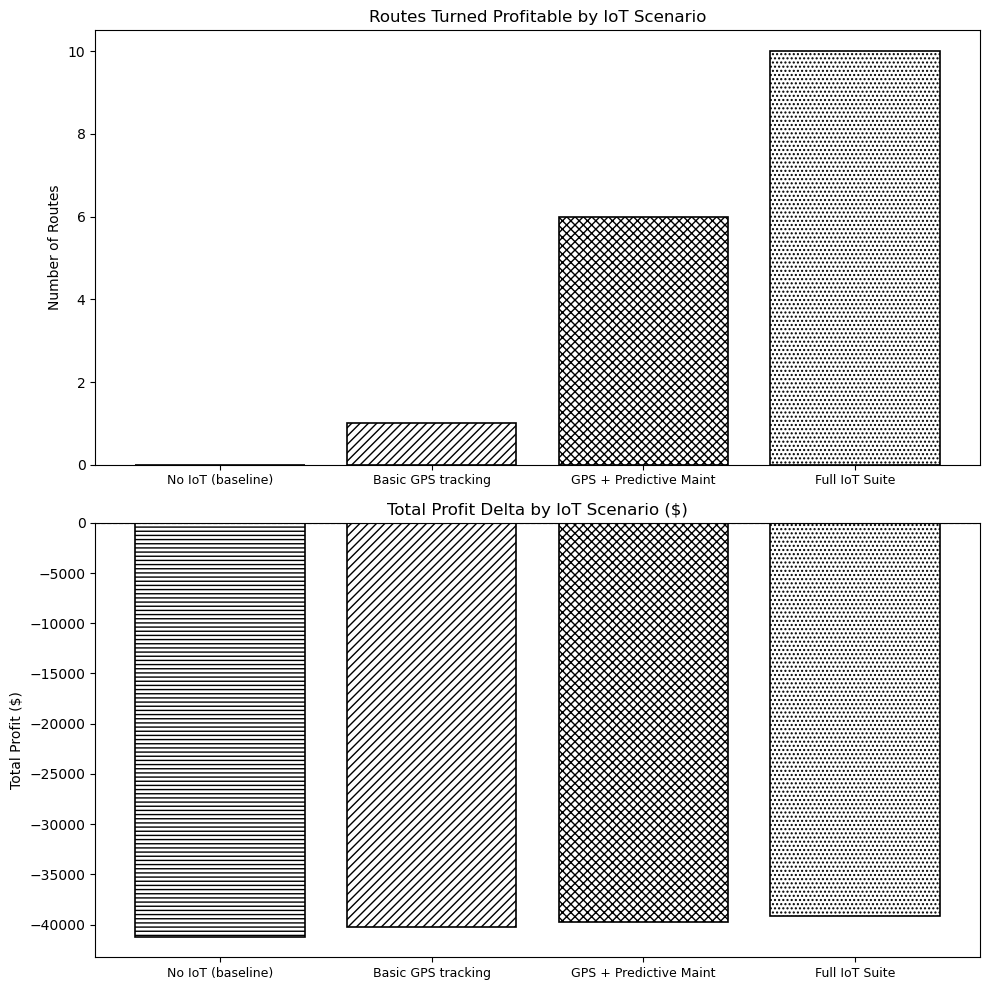

In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import Rectangle
import numpy as np

scenario_order = ["No IoT (baseline)", "Basic GPS tracking", "GPS + Predictive Maint", "Full IoT Suite"]
summary["scenario"] = pd.Categorical(summary["scenario"], categories=scenario_order, ordered=True)
summary = summary.sort_values("scenario")

# Define hatching patterns (B&W, like the reference image)
hatches = ['----', '////', 'xxxx', '....']
edge_colors = ['black', 'black', 'black', 'black']
face_colors = ['white', 'white', 'white', 'white']

fig, axes = plt.subplots(2, 1, figsize=(10, 10))  # 2 rows, 1 col = top and bottom

# --- Top chart ---
bars0 = axes[0].bar(
    summary["scenario"],
    summary["routes_turned_profitable"],
    color=face_colors,
    edgecolor=edge_colors,
    hatch=hatches,
    linewidth=1.2
)
axes[0].set_title("Routes Turned Profitable by IoT Scenario")
axes[0].set_ylabel("Number of Routes")
axes[0].set_xticklabels(summary["scenario"], rotation=0, ha="center", fontsize=9)

# --- Bottom chart ---
bars1 = axes[1].bar(
    summary["scenario"],
    summary["total_profit_delta"],
    color=face_colors,
    edgecolor=edge_colors,
    hatch=hatches,
    linewidth=1.2
)
axes[1].set_title("Total Profit Delta by IoT Scenario ($)")
axes[1].set_ylabel("Total Profit ($)")
axes[1].set_xticklabels(summary["scenario"], rotation=0, ha="center", fontsize=9)
axes[1].axhline(0, color="black", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.savefig("iot_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

Before/After Folium map (red = still losing, green = recovered)

In [19]:
def haversine_km(c1, c2):
    R = 6371
    lat1, lon1 = math.radians(c1[0]), math.radians(c1[1])
    lat2, lon2 = math.radians(c2[0]), math.radians(c2[1])
    dlat, dlon = lat2 - lat1, lon2 - lon1
    a = math.sin(dlat/2)**2 + math.cos(lat1)*math.cos(lat2)*math.sin(dlon/2)**2
    return round(R * 2 * math.asin(math.sqrt(a)), 1)

# Pick the "Full IoT Suite" scenario to show the best case
best_scenario = sim_df[sim_df["scenario"] == "Full IoT Suite"].copy()

m_iot = folium.Map(location=[39.5, -98.35], zoom_start=4, tiles="CartoDB dark_matter")

for _, row in best_scenario.iterrows():
    cust_coords  = (row["customer_latitude"],  row["customer_longitude"])
    order_coords = (row["order_latitude"],     row["order_longitude"])

    if any(pd.isna(c) for c in cust_coords + order_coords):
        continue

    dist_km = haversine_km(cust_coords, order_coords)

    # Green if now profitable, red if still losing
    color = "#2ecc71" if row["now_profitable"] else "#e74c3c"

    folium.PolyLine(
        locations=[cust_coords, order_coords],
        color=color,
        weight=2,
        opacity=0.8,
        tooltip=(
            f"{row['Customer City']} → {row['Order City']} | "
            f"{dist_km} km | "
            f"Old profit: ${row['profit_sum']:.0f} | "
            f"New profit: ${row['new_profit_sum']:.0f} | "
            f"Delay cut: {row['p90_delay']:.1f} → {row['new_p90_delay']:.1f} days"
        )
    ).add_to(m_iot)

    # Customer dot
    folium.CircleMarker(
        location=cust_coords, radius=4,
        color="#3498db", fill=True, fill_opacity=0.9,
        tooltip=f"Customer: {row['Customer City']}, {row['Customer State']}"
    ).add_to(m_iot)

    # Order dot
    folium.CircleMarker(
        location=order_coords, radius=4,
        color="#9b59b6", fill=True, fill_opacity=0.9,
        tooltip=f"Order: {row['Order City']}, {row['Order State']}"
    ).add_to(m_iot)

m_iot.save("iot_simulation_map.html")
print("Map saved → iot_simulation_map.html")


Map saved → iot_simulation_map.html


Summary

In [23]:
baseline = summary[summary["scenario"] == "No IoT (baseline)"]
full_iot  = summary[summary["scenario"] == "Full IoT Suite"]

total_losing = len(final_df)
recovered    = int(full_iot["routes_turned_profitable"].values[0])
profit_gain  = full_iot["total_profit_delta"].values[0]

print(f"""
=== IoT Simulation Summary ===
Total loss-making First Class routes : {total_losing}
Routes recovered with Full IoT Suite : {recovered}  ({recovered/total_losing*100:.1f}%)
Total profit delta (Full IoT)        : ${profit_gain:,.0f}""")




=== IoT Simulation Summary ===
Total loss-making First Class routes : 208
Routes recovered with Full IoT Suite : 10  (4.8%)
Total profit delta (Full IoT)        : $-39,145
